# Final prediction

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path

ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / 'clean').is_dir())
OUT = ROOT / 'output' / 'polls'
OUT.mkdir(parents=True, exist_ok=True)
polls = pd.read_csv(ROOT / 'clean' / 'polls' / 'ohio_senate_polls.csv', parse_dates=['start', 'end'])
polls['affiliation'] = polls.affiliation.fillna('')
polls[['end', 'pollster', 'affiliation', 'voter_type', 'n', 'brown', 'husted', 'margin_2p']]

,end,pollster,affiliation,voter_type,n,brown,husted,margin_2p
0,2025-12-08,Emerson College,,RV,850,46,49,-3.157895
1,2026-02-22,EMC Research,D,LV,1343,51,47,4.081633
2,2026-03-08,OnMessage Inc.,,LV,600,47,45,2.173913
3,2026-03-14,Quantus Insights,,LV,784,44,46,-2.222222
4,2026-04-09,Echelon Insights,,LV,413,45,51,-6.250000
5,2026-04-14,Bowling Green State University Democracy and P...,,RV,1000,47,50,-3.092784
6,2026-06-01,Beacon Research/Shaw & Co. Research,,RV,1015,53,45,8.163265
7,2026-06-04,Tulchin Research,D,LV,600,46,42,4.545455
8,2026-06-16,Fabrizio Lee & Associates/Impact Research,,LV,800,48,45,3.225806
9,2026-06-28,The New York Times/Siena College,,LV,601,47,50,-3.092784


In [2]:
# likely voters, nonpartisan; final three weeks = last field day on or after Oct 13
ELECTION = pd.Timestamp('2026-11-03')
WINDOW_START = ELECTION - pd.Timedelta(days=21)
lv = polls[(polls.voter_type == 'LV') & (polls.affiliation == '')]
recent = lv[lv.end >= WINDOW_START].sort_values('end')
since_aug = lv[lv.end >= '2026-08-01']
avg = recent.margin_2p.mean()
avg_n = np.average(recent.margin_2p, weights=recent.n)
print(len(since_aug), len(recent))
recent[['end', 'pollster', 'n', 'margin_2p', 'se_2p']]

16 5


,end,pollster,n,margin_2p,se_2p
26,2026-10-13,New River Strategies/GS Strategy Group,959,6.521739,3.359473
28,2026-10-18,Marist College,1176,4.347826,3.037327
29,2026-10-19,Beacon Research/Shaw & Co. Research,1592,5.050505,2.515685
30,2026-10-20,Verasight,531,4.347826,4.520099
31,2026-10-22,InsiderAdvantage,1200,3.296703,3.024493


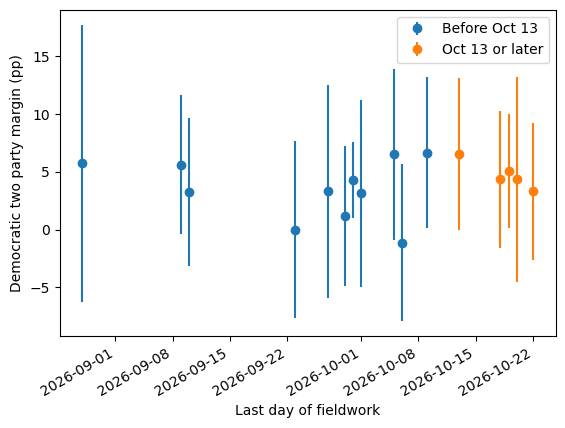

In [3]:
# Figure 4: polls since August, 95% sampling intervals
fig, ax = plt.subplots()
early = since_aug[since_aug.end < WINDOW_START]
ax.errorbar(early.end, early.margin_2p, yerr=1.96 * early.se_2p, fmt='o', label='Before Oct 13')
ax.errorbar(recent.end, recent.margin_2p, yerr=1.96 * recent.se_2p, fmt='o', label='Oct 13 or later')
ax.set(xlabel='Last day of fieldwork', ylabel='Democratic two party margin (pp)')
ax.legend()
fig.autofmt_xdate()
fig.savefig(OUT / 'poll_margins_over_time.png', dpi=200)
plt.show()

In [4]:
# Table 3, top
pd.Series({'Polls': len(recent), 'Respondents': recent.n.sum(), 'Mean': avg, 'Sample-weighted mean': avg_n,
           'Median': recent.margin_2p.median(), 'SD': recent.margin_2p.std(),
           'Min': recent.margin_2p.min(), 'Max': recent.margin_2p.max()}).round(2)

Polls                      5.00
Respondents             5458.00
Mean                       4.71
Sample-weighted mean       4.70
Median                     4.35
SD                         1.19
Min                        3.30
Max                        6.52
dtype: float64

In [5]:
# Table 3, bottom: Senate polling error 2022 and 2024 (actual minus poll average)
err = pd.read_csv(ROOT / 'clean' / 'polls' / 'senate_poll_error.csv')
err_tab = pd.concat([err.groupby('year').error.agg(['count', 'mean', 'std']),
                     err.error.agg(['count', 'mean', 'std']).to_frame('pooled').T])
print(err[err.state_po == 'OH'][['year', 'poll_avg', 'actual', 'error']].round(1))
err_tab.round(2)

    year  poll_avg  actual  error
11  2022      -4.9    -6.1   -1.2
27  2024      -2.4    -3.7   -1.4


,count,mean,std
2022,19.0,-2.34,5.76
2024,15.0,-2.48,3.97
pooled,34.0,-2.40,4.98


In [6]:
# poll-based estimate: average + mean historical error
bias = err.error.mean()
poll_estimate = avg + bias
print(round(avg, 2), round(bias, 2), round(poll_estimate, 2))
FORECAST_OUT = ROOT / 'output' / 'forecast'
pd.DataFrame([{'poll_avg_pp': avg, 'poll_avg_n_pp': avg_n, 'bias_pp': bias,
               'poll_estimate_pp': poll_estimate}]).to_csv(FORECAST_OUT / 'poll_forecast.csv', index=False)

4.71 -2.4 2.31


baseline (lean + constant)   +41.17
midterm (R president)        +2.45
lagged Senate share          +6.96
Brown appeal                 +2.25
polls (50/50) ½ × (51.2 − 52.8) poll margin +2.3 -0.83
adjusted baseline 52.83%, poll-based 51.16%, final 51.99% (margin +4.0)


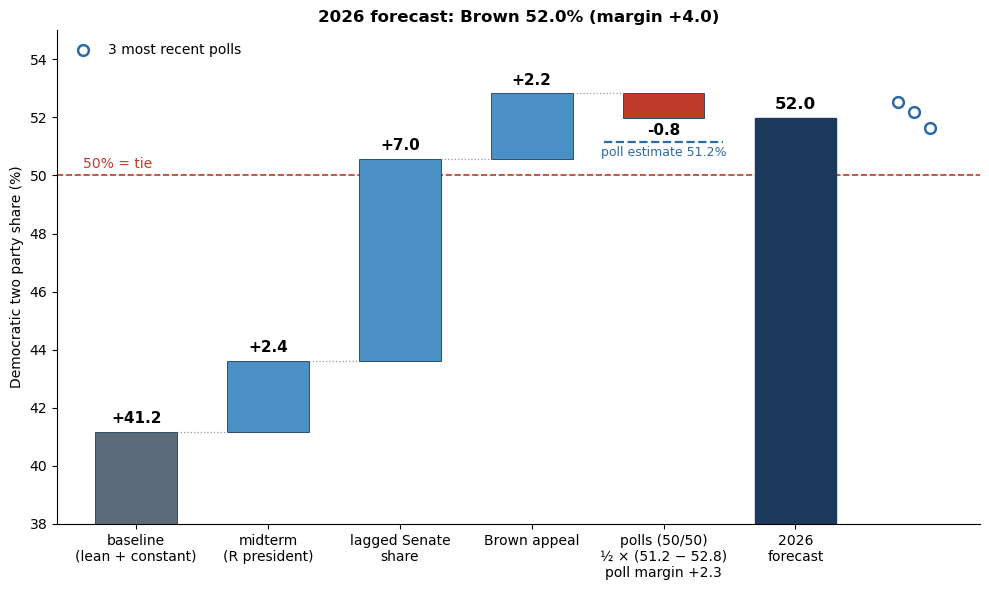

In [7]:
# AI was used to create this graph
# Figure 10: baseline terms, Brown appeal, 50/50 with polls (two party share, %)
F = ROOT / 'output' / 'forecast'
B = pd.read_csv(F / 'baseline_forecast.csv').iloc[0]
A = pd.read_csv(F / 'brown_adjustment.csv').iloc[0]
pf = pd.read_csv(F / 'poll_forecast.csv').iloc[0]
share = lambda margin_pp: 50 + margin_pp / 2

adjusted = share(B.margin_pp + A.adjust_pp)
poll_share = share(pf.poll_estimate_pp)
final = 0.5 * adjusted + 0.5 * poll_share
steps = [('baseline\n(lean + constant)', (B.b0 + B.b_lean * B.lean_OH) * 100),
         ('midterm\n(R president)', B.b_midR * 100),
         ('lagged Senate\nshare', B.b_S_lag * B.S_lag_OH * 100),
         ('Brown appeal', A.adjust_pp / 2),
         ('polls (50/50)\n½ × ({:.1f} − {:.1f})\npoll margin {:+.1f}'.format(poll_share, 50 + (B.margin_pp + A.adjust_pp) / 2, pf.poll_estimate_pp), final - adjusted)]
print('\n'.join(f'{k.replace(chr(10), " "):28s} {v:+.2f}' for k, v in steps))
print(f'adjusted baseline {adjusted:.2f}%, poll-based {poll_share:.2f}%, final {final:.2f}% (margin {(2*final-100):+.1f})')

fig, ax = plt.subplots(figsize=(10, 6))
cum = np.cumsum([v for _, v in steps])
starts = np.concatenate([[0], cum[:-1]])
for i, ((lab, v), st) in enumerate(zip(steps, starts)):
    col = '#5b6b7a' if i == 0 else ('#4a90c4' if v >= 0 else '#c0392b')
    ax.bar(i, v, bottom=st, color=col, edgecolor='#1b3a5c', linewidth=.6, width=.62)
    ax.annotate(f'{v:+.1f}', (i, st + v), ha='center',
                va='bottom' if v >= 0 else 'top', fontsize=11, fontweight='bold',
                xytext=(0, 4 if v >= 0 else -4), textcoords='offset points')
    if i < len(steps) - 1:
        ax.plot([i + .31, i + 1 - .31], [cum[i]] * 2, color='#8c9aa8', lw=.9, ls=':')
n = len(steps)
ax.hlines(poll_share, n - 1 - .45, n - 1 + .45, color='#2f6aa3', lw=1.6, ls='--')
ax.annotate(f'poll estimate {poll_share:.1f}%', (n - 1, poll_share), ha='center', va='top',
            fontsize=9, color='#2f6aa3', xytext=(0, -3), textcoords='offset points')
ax.bar(n, final, color='#1b3a5c', edgecolor='#1b3a5c', width=.62)
ax.annotate(f'{final:.1f}', (n, final), ha='center', va='bottom', fontsize=12, fontweight='bold',
            xytext=(0, 4), textcoords='offset points')
last3 = recent.sort_values('end').tail(3)
xp = n + 0.9 + np.linspace(-.12, .12, len(last3))
ax.scatter(xp, last3.dem2p * 100, s=60, facecolor='white', edgecolor='#2f6aa3', linewidth=1.8,
           zorder=4, label=f'{len(last3)} most recent polls')
ax.axhline(50, color='#c0392b', lw=1.2, ls='--', zorder=0)
ax.annotate('50% = tie', (-0.4, 50), fontsize=10, color='#c0392b', va='bottom',
            xytext=(0, 3), textcoords='offset points')
ax.set_xticks(list(range(n + 1)), [lab for lab, _ in steps] + ['2026\nforecast'])
ax.set_xlim(-0.6, n + 1.4)
ax.set_ylim(38, 55)
ax.set_ylabel('Democratic two party share (%)')
ax.set_title(f'2026 forecast: Brown {final:.1f}% (margin {2*final-100:+.1f})', fontweight='bold')
ax.legend(frameon=False, loc='upper left')
ax.spines[['top', 'right']].set_visible(False)
fig.tight_layout()
fig.savefig(F / 'forecast_waterfall.png', dpi=200)
plt.show()